# Number of layers of a phytoplankton cell model

Companion of `sensitivity_multilayer_particles.ipynb` and `sensitivity_core_particles.ipynb`: how many
concentric layers are needed to represent the optical properties of a phytoplankton cell? A reference cell of
**15 layers**, from the outer wall (theca, frustule or coccoliths) and the lipid bilayer membranes down to the
nucleolus, is simplified into models of **1 to 15 layers** by merging adjacent layers. Efficiency factors,
asymmetry parameter, backscattering ratio and scattering matrix are computed with exact multilayer Mie theory
([scattnlay](https://github.com/ovidiopr/scattnlay); Peña and Pal, 2009).

**Reference cell** (outer to inner; refractive indices relative to seawater, $n_w$ = 1.34):

| # | layer | $n$ | $m$ | size |
|---|---|---|---|---|
| 1 | wall: cellulose theca / silica frustule / calcite coccoliths | 1.55 / 1.46 / 1.60 | 1.157 / 1.090 / 1.194 | 2 % of the radius |
| 2 | plasma membrane (lipid bilayer) | 1.46 | 1.090 | 8 nm |
| 3 | peripheral cytoplasm | 1.367 | 1.02 | 5 % of the volume |
| 4 | chloroplast outer envelope membrane | 1.46 | 1.090 | 8 nm |
| 5 | chloroplast intermembrane space | 1.353 | 1.01 | 10 nm |
| 6 | chloroplast inner envelope membrane | 1.46 | 1.090 | 8 nm |
| 7 | stroma | 1.394 | 1.04 | 2 % of the volume |
| 8 | thylakoids (pigment–protein complexes, all the pigments) | 1.50 | 1.12 | 20 % of the volume |
| 9 | stroma | 1.394 | 1.04 | 3 % of the volume |
| 10 | cytoplasm | 1.367 | 1.02 | rest of the volume |
| 11 | nuclear envelope, outer membrane | 1.46 | 1.090 | 8 nm |
| 12 | perinuclear space | 1.353 | 1.01 | 20 nm |
| 13 | nuclear envelope, inner membrane | 1.46 | 1.090 | 8 nm |
| 14 | nucleoplasm (chromatin) | 1.394 | 1.04 | 8 % of the volume |
| 15 | nucleolus | 1.42 | 1.06 | 2 % of the volume |

The membranes have a fixed thickness, so the relative layer radii change with the cell size; the wall and the
compartments scale with the cell.

**Models of 1 to 15 layers**: the boundaries of the reference cell are introduced one at a time, the layers
between them being merged into one layer of volume-averaged complex refractive index. All the models therefore
have the same volume-averaged index and the same amount of pigment: only the internal structure differs. The
order follows the size of the compartments (membranes last):

1. homogeneous cell,
2. wall,
3. chloroplast region / inner cytoplasm,
4. nucleus,
5. chloroplast outer boundary,
6. – 7. thylakoid layer,
8. nucleolus,
9. – 12. plasma membrane and chloroplast envelope,
13. – 15. nuclear envelope.

**Absorption**: non-absorbing cells, or pigments in the thylakoid layer with the volume-averaged imaginary part
of the companion notebooks.

**Size distributions**: cell radius from 0.5 to 40 µm (cell diameters of 1 to 80 µm), Junge and log-normal
distributions, wavelengths in water at the OLCI bands.

**Requirements**: `pip install scattnlay` (GPL-3.0). If its import fails with
`GLIBCXX_3.4.32 not found` in an Anaconda environment, update the C++ runtime of the environment
(`conda install -c conda-forge "libstdcxx-ng>=13"`) or start Jupyter with
`LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libstdc++.so.6`. The computations take a few minutes on 40 CPUs.

## 1. Setup

In [1]:
import os

# one BLAS thread per process: the scattering computations run in one process per CPU,
# and multithreaded BLAS in each of them oversubscribes the CPUs (and can stall the workers)
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[var] = '1'

import time

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scattnlay import scattcoeffs, scattnlay

from mopsmap_tbx.opac_mopsmap import ROOT

odir = ROOT / 'scatmat' / 'sensitivity'
odir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
N_COLORS = ['#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b']   # number of layers (ordinal)
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']                   # categorical
print('dask', dask.__version__)

dask 2024.8.0


In [2]:
n_w = 1.34
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                                  # wavelength in water (µm)

r_min, r_max = 0.5, 40.                                 # cell radius (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1000)
theta = np.concatenate([[0, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.4], np.arange(0.5, 180.1, 0.5)])
mu = np.cos(np.radians(theta))


def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


psd_def = {
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
    'LN10': ('log-normal', 'r_mod = 10 µm', lognormal(r, 10., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])
weights = n_r * dr                                       # (psd, r) quadrature weights

# volume-averaged imaginary part (pigment spectrum of the companion notebooks)
mi_pigment = 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15)

## 2. Cell models

`LAYERS` describes the reference cell from the outside: (name, refractive index, size type, size). The size is a
fraction of the cell radius (`radius`), a thickness in µm (`thickness`), a fraction of the cell volume
(`volume`) or the rest of the volume (`rest`). `SPLITS` gives the order in which the boundaries are introduced
(boundary $b$ separates the layers $b-1$ and $b$, numbered from 0 at the wall).

In [3]:
m_membrane = 1.46 / n_w   # lipid bilayer
d_membrane = 0.008        # µm
walls = {'theca': 1.55 / n_w, 'silica': 1.46 / n_w, 'calcite': 1.60 / n_w}
LAYERS = [
    ('wall', None, 'radius', 0.02),
    ('plasma membrane', m_membrane, 'thickness', d_membrane),
    ('peripheral cytoplasm', 1.02, 'volume', 0.05),
    ('chloroplast outer membrane', m_membrane, 'thickness', d_membrane),
    ('chloroplast intermembrane space', 1.01, 'thickness', 0.010),
    ('chloroplast inner membrane', m_membrane, 'thickness', d_membrane),
    ('stroma', 1.04, 'volume', 0.02),
    ('thylakoids', 1.12, 'volume', 0.20),
    ('stroma ', 1.04, 'volume', 0.03),
    ('cytoplasm', 1.02, 'rest', None),
    ('nuclear outer membrane', m_membrane, 'thickness', d_membrane),
    ('perinuclear space', 1.01, 'thickness', 0.020),
    ('nuclear inner membrane', m_membrane, 'thickness', d_membrane),
    ('nucleoplasm', 1.04, 'volume', 0.08),
    ('nucleolus', 1.06, 'volume', 0.02),
]
I_THYLAKOIDS = 7
SPLITS = [1, 9, 13, 6, 7, 8, 14, 2, 3, 4, 5, 10, 11, 12]
n_layers = np.arange(1, len(LAYERS) + 1)
absorptions = ['none', 'pigment']


def geometry(R):
    # outer radius (µm) of each layer of the reference cell (outer -> inner) for a cell radius R (µm)
    outer = np.empty(len(LAYERS))
    i_rest = [layer[2] for layer in LAYERS].index('rest')
    rad = R
    for i in range(i_rest):
        outer[i] = rad
        kind, size = LAYERS[i][2:]
        if kind == 'radius':
            rad -= size * R
        elif kind == 'thickness':
            rad -= size
        else:
            rad = np.cbrt(rad ** 3 - size * R ** 3)
    outer[i_rest] = rad
    rad = 0.
    for i in range(len(LAYERS) - 1, i_rest, -1):
        kind, size = LAYERS[i][2:]
        rad = rad + size if kind == 'thickness' else np.cbrt(rad ** 3 + size * R ** 3)
        outer[i] = rad
    assert outer[i_rest + 1] < outer[i_rest], 'cell too small for its layers'
    return outer


def layer_indices(wall, absorption):
    # complex refractive index (wl, layer) of the reference cell
    m = np.array([[walls[wall] if layer[1] is None else layer[1] for layer in LAYERS]] * len(wl), complex)
    if absorption == 'pigment':
        m[:, I_THYLAKOIDS] += 1j * mi_pigment / LAYERS[I_THYLAKOIDS][3]
    return m


def merge(outer, m, n):
    # model of n layers: outer radii and volume-averaged indices, from the core outward (scattnlay order)
    inner = np.append(outer[1:], 0.)
    vol = outer ** 3 - inner ** 3
    groups = np.split(np.arange(len(outer)), sorted(SPLITS[:n - 1]))
    rad = np.array([outer[g[0]] for g in groups])
    mg = np.array([np.sum(vol[g] * m[g]) / np.sum(vol[g]) for g in groups])
    return rad[::-1], mg[::-1]


R = 5.
outer = geometry(R)
table = pd.DataFrame({'layer': [layer[0].strip() for layer in LAYERS],
                      'm (theca)': layer_indices('theca', 'none')[0].real.round(3),
                      'outer radius / R (R = 0.5 µm)': geometry(0.5) / 0.5,
                      'outer radius / R (R = 5 µm)': outer / R,
                      'outer radius / R (R = 40 µm)': geometry(40.) / 40.},
                     index=pd.RangeIndex(1, len(LAYERS) + 1, name='#'))
table.round(4)

,layer,m (theca),outer radius / R (R = 0.5 µm),outer radius / R (R = 5 µm),outer radius / R (R = 40 µm)
#,,,,,
1,wall,1.157,1.0000,1.0000,1.0000
2,plasma membrane,1.090,0.9800,0.9800,0.9800
3,peripheral cytoplasm,1.020,0.9640,0.9784,0.9798
4,chloroplast outer membrane,1.090,0.9457,0.9607,0.9621
5,chloroplast intermembrane space,1.010,0.9297,0.9591,0.9619
6,chloroplast inner membrane,1.090,0.9097,0.9571,0.9617
7,stroma,1.040,0.8937,0.9555,0.9615
8,thylakoids,1.120,0.8853,0.9481,0.9542
9,stroma,1.040,0.7904,0.8672,0.8745


The refinement from 1 to 15 layers, for a cell of radius 1 µm: refractive index along the radius for each
model (right: zoom on the outer part, with the wall, the plasma membrane and the chloroplast envelope).

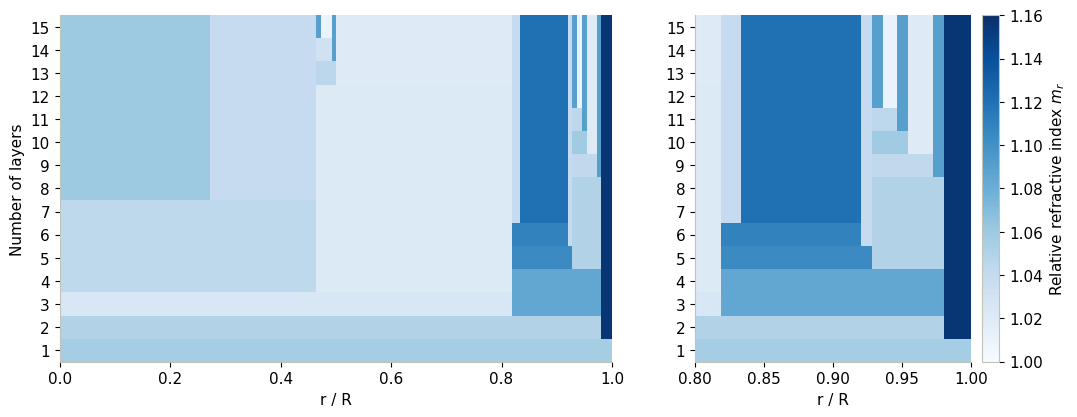

In [4]:
R = 1.
x = np.linspace(0, R, 4000)
outer = geometry(R)
m_ref = layer_indices('theca', 'none')[0]
img = np.empty((len(n_layers), len(x)))
for j, n in enumerate(n_layers):
    rad, mg = merge(outer, m_ref, n)
    img[j] = mg.real[np.minimum(np.searchsorted(rad, x), len(rad) - 1)]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})
for ax, xlim in zip(axs, [(0, 1), (0.8, 1)]):
    pc = ax.pcolormesh(x / R, n_layers, img, cmap='Blues', vmin=1.0, vmax=1.16, shading='nearest')
    ax.set_xlim(xlim)
    ax.set_yticks(n_layers)
    ax.grid(False)
    ax.set_xlabel('r / R')
axs[0].set_ylabel('Number of layers')
fig.colorbar(pc, ax=axs, label='Relative refractive index $m_r$', pad=0.01)
plt.show()

## 3. Multilayer Mie computations

Same method as the companion notebooks: multipole coefficients $a_n, b_n$ from `scattcoeffs`, efficiency factors
and asymmetry parameter from `scattnlay`, amplitude functions summed with tabulated angular functions, and
scattering matrix normalized as in MOPSMAP ($a_1 = a_2 = 4\langle S_{11}\rangle / \langle x^2 Q_{sca}\rangle$,
$a_3 = a_4 \propto \langle S_{33}\rangle$, $b_1 \propto \langle S_{12}\rangle$, $b_2 \propto -\langle S_{34}\rangle$).
The layer radii are recomputed for each cell radius.

In [5]:
NMAX = 1200   # larger than the number of terms used by scattnlay for x = 842 with 15 layers (1020)


def angular_functions(mu, nmax=NMAX):
    # pi_n and tau_n (n = 0..nmax) at the cosines mu
    pi = np.zeros((nmax + 1, len(mu)))
    tau = np.zeros_like(pi)
    pi[1] = 1.
    for n in range(2, nmax + 1):
        pi[n] = ((2 * n - 1) * mu * pi[n - 1] - n * pi[n - 2]) / (n - 1)
    n = np.arange(1, nmax + 1)[:, None]
    tau[1:] = n * mu * pi[1:] - (n + 1) * pi[:-1]
    return pi, tau


def amplitudes(x_layers, m_layers, pi, tau):
    # S1, S2 of a layered sphere from its multipole coefficients
    terms, an, bn = scattcoeffs(x_layers, m_layers)
    n = np.arange(1, len(an) + 1)
    f = (2 * n + 1) / (n * (n + 1))
    A, B = f * an, f * bn
    P, T = pi[1:len(an) + 1], tau[1:len(an) + 1]
    return A @ P + B @ T, A @ T + B @ P


# checks: amplitude functions of the 15-layer cell against scattnlay's own, at the largest size parameter,
# and 15 layers of identical index against a homogeneous sphere
pi, tau = angular_functions(mu)
k = 2 * np.pi / wl_w[0]
rad, m = merge(geometry(40.), layer_indices('calcite', 'pigment')[0], 15)
S1, S2 = amplitudes(k * rad, m, pi, tau)
ref = scattnlay(k * rad, m, np.radians(theta))
err = np.max(np.abs((np.abs(S1) ** 2 + np.abs(S2) ** 2) / (np.abs(ref[8]) ** 2 + np.abs(ref[9]) ** 2) - 1))
print(f'15 layers, x = {k * 40:.0f}: max relative difference of S11 = {err:.1e}')
q15 = scattnlay(k * rad, np.full(15, 1.05 + 0.001j))
q1 = scattnlay(k * rad[-1:], np.array([1.05 + 0.001j]))
print(f'15 identical layers vs homogeneous: Qext {q15[1]:.10f} / {q1[1]:.10f}, g {q15[6]:.10f} / {q1[6]:.10f}')

15 layers, x = 842: max relative difference of S11 = 2.8e-14
15 identical layers vs homogeneous: Qext 2.0172198472 / 2.0172198472, g 0.9953997426 / 0.9953997426


In [6]:
@dask.delayed
def cell_case(n, m_cell, wl_w, r, mu, weights):
    # size-averaged Qext, ssa, g (psd,) and scattering matrix (psd, theta, element) of the n-layer model
    import numpy as np
    from scattnlay import scattnlay

    pi, tau = angular_functions(mu)
    k = 2 * np.pi / wl_w
    qext, qsca, g = (np.empty(len(r)) for _ in range(3))
    S11, S12, S33, S34 = (np.empty((len(r), len(mu))) for _ in range(4))
    for i, ri in enumerate(r):
        rad, m = merge(geometry(ri), m_cell, n)
        X = k * rad
        out = scattnlay(X, m)
        qext[i], qsca[i], g[i] = out[1], out[2], out[6]
        S1, S2 = amplitudes(X, m, pi, tau)
        S11[i] = (np.abs(S2) ** 2 + np.abs(S1) ** 2) / 2
        S12[i] = (np.abs(S2) ** 2 - np.abs(S1) ** 2) / 2
        S33[i] = np.real(S2 * np.conj(S1))
        S34[i] = np.imag(S2 * np.conj(S1))
    x = k * r
    G = np.pi * r ** 2
    Qext = weights @ (G * qext) / (weights @ G)
    Qsca = weights @ (G * qsca) / (weights @ G)
    gg = weights @ (G * qsca * g) / (weights @ (G * qsca))
    den = (weights @ (x ** 2 * qsca))[:, None] / 4
    a1, a3 = weights @ S11 / den, weights @ S33 / den
    b1, b2 = weights @ S12 / den, -(weights @ S34) / den
    return Qext, Qsca / Qext, gg, np.stack([a1, a1, a3, a3, b1, b2], axis=-1).astype('float32')


keys = [(a, w, n) for a in absorptions for w in walls for n in n_layers]
tasks = []
for a, w, n in keys:
    m_cell = layer_indices(w, a)
    tasks += [cell_case(n, m_cell[iw], wl_w[iw], r, mu, weights) for iw in range(len(wl))]
print(len(keys), 'cell models,', len(tasks), 'tasks')
t0 = time.perf_counter()
res = dask.compute(*tasks, scheduler='processes', num_workers=os.cpu_count())
print(f'done in {time.perf_counter() - t0:.0f} s')

90 cell models, 1440 tasks


done in 269 s


### Gathering the results

In [7]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']
out = [np.array([x[i] for x in res]) for i in range(4)]
shape = (len(absorptions), len(walls), len(n_layers), len(wl))
out = [o.reshape(shape + o.shape[1:]) for o in out]
dims = ('absorption', 'wall', 'n_layers', 'wl', 'psd')
ds = xr.Dataset({'Qext': (dims, out[0]), 'ssa': (dims, out[1]), 'g': (dims, out[2]),
                 'F': (dims + ('theta', 'element'), out[3])},
                coords=dict(absorption=absorptions, wall=list(walls), n_layers=n_layers, wl=wl, psd=psd_ids,
                            theta=theta, element=elements))
ds = ds.assign_coords(theta_rad=('theta', np.radians(theta)))
a1 = ds.F.sel(element='a1')
a1s = a1 * np.sin(ds.theta_rad)
ds['bb_ratio'] = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad') / a1s.integrate('theta_rad')
ds['Qsca'] = ds.Qext * ds.ssa
ds['Qabs'] = ds.Qext - ds.Qsca
ds['Qbb'] = ds.Qsca * ds.bb_ratio
ds['dolp'] = -ds.F.sel(element='b1') / a1
ds

<xarray.Dataset> Size: 90MB
Dimensions:     (absorption: 2, wall: 3, n_layers: 15, wl: 16, psd: 6,
                 theta: 369, element: 6)
Coordinates:
  * absorption  (absorption) <U7 56B 'none' 'pigment'
  * wall        (wall) <U7 84B 'theca' 'silica' 'calcite'
  * n_layers    (n_layers) int64 120B 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
  * wl          (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * psd         (psd) <U4 96B 'J3.5' 'J4.0' 'LN1' 'LN2' 'LN5' 'LN10'
  * theta       (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element     (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
    theta_rad   (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.133 3.142
Data variables:
    Qext        (absorption, wall, n_layers, wl, psd) float64 69kB 2.064 ... ...
    ssa         (absorption, wall, n_layers, wl, psd) float64 69kB 1.0 ... 0....
    g           (absorption, wall, n_layers, wl, psd) float64 69kB 0.9858 ......
    F           (absorption, wall, n_layers, wl, psd, theta, element) float32 77MB ...
    bb_ratio    (absorption, wall, n_layers, wl, psd) float64 69kB 0.001473 ....
    Qsca        (absorption, wall, n_layers, wl, psd) float64 69kB 2.064 ... ...
    Qabs        (absorption, wall, n_layers, wl, psd) float64 69kB 4.441e-16 ...
    Qbb         (absorption, wall, n_layers, wl, psd) float64 69kB 0.003041 ....
    dolp        (absorption, wall, n_layers, wl, psd, theta) float32 13MB -0....

## 4. Sensitivity to the number of layers

### Optical properties as a function of the number of layers

Non-absorbing cells at 560 nm (first three columns) and $Q_{abs}$ of pigmented cells at 442.5 nm, for the three
walls. The gray band marks the steps that resolve the membranes (9–15 layers).

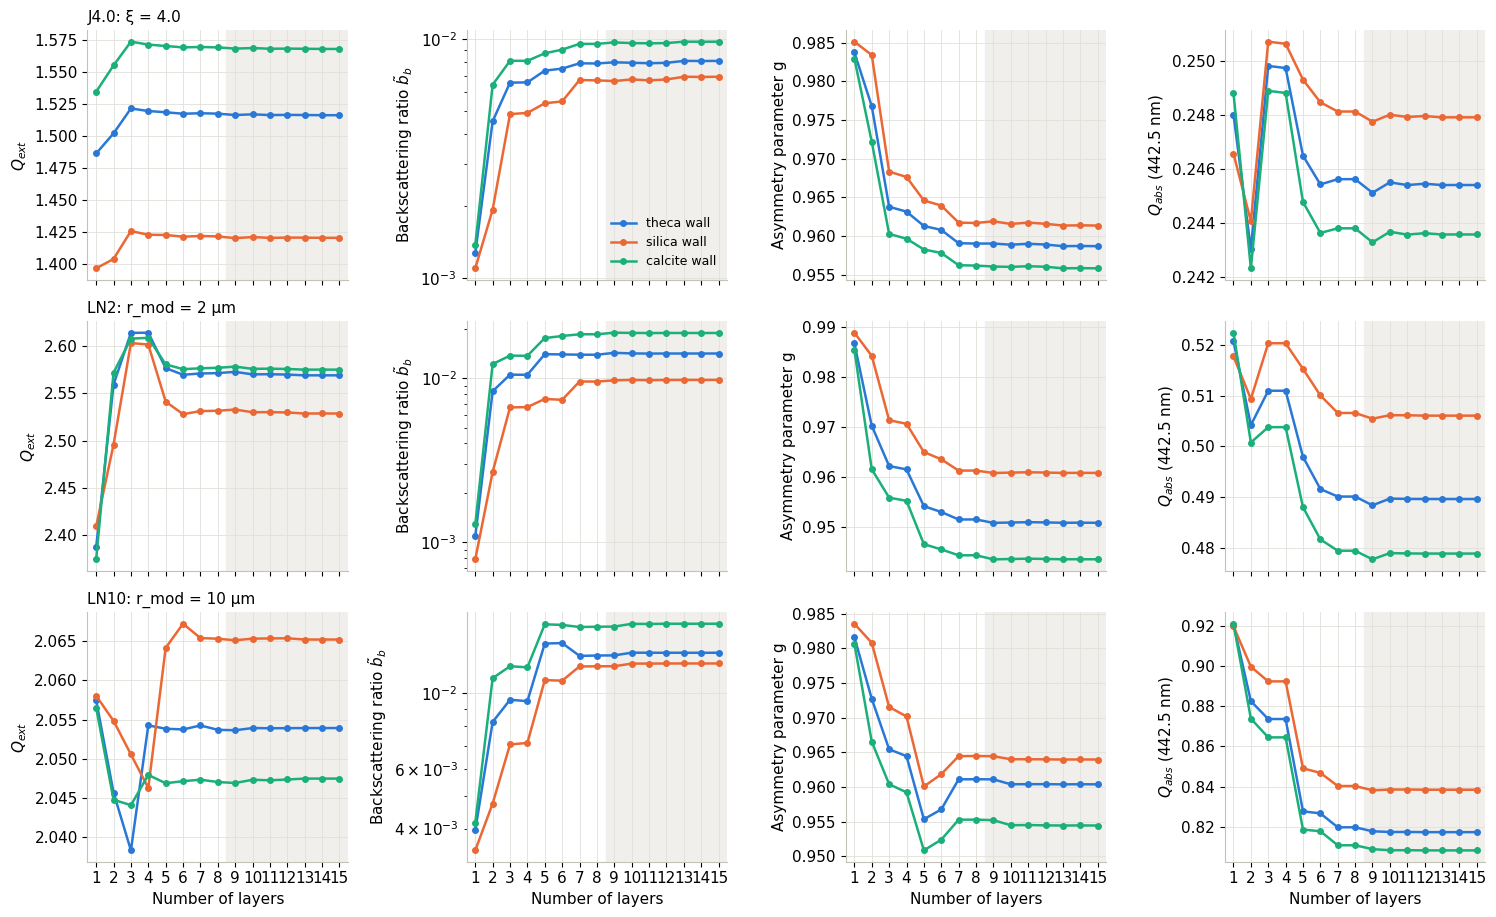

In [8]:
panels = [('Qext', 'none', 560, '$Q_{ext}$'), ('bb_ratio', 'none', 560, 'Backscattering ratio $\\tilde{b}_b$'),
          ('g', 'none', 560, 'Asymmetry parameter g'), ('Qabs', 'pigment', 442.5, '$Q_{abs}$ (442.5 nm)')]
psds = ['J4.0', 'LN2', 'LN10']
fig, axs = plt.subplots(len(psds), 4, figsize=(15, 3.1 * len(psds)), sharex=True)
for i, p in enumerate(psds):
    for j, (v, a, w, label) in enumerate(panels):
        ax = axs[i, j]
        for wall, c in zip(walls, CAT):
            ax.plot(n_layers, ds[v].sel(absorption=a, wl=w, psd=p, wall=wall), 'o-', ms=4, color=c, label=f'{wall} wall')
        ax.axvspan(8.5, 15.5, color='#f0efec', zorder=-2)
        if v == 'bb_ratio':
            ax.set_yscale('log')
        ax.set_ylabel(label)
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[-1]:
    ax.set_xlabel('Number of layers')
    ax.set_xticks(n_layers)
    ax.set_xlim(0.5, 15.5)
axs[0, 1].legend(frameon=False)
plt.tight_layout()

### Convergence towards the 15-layer cell

Relative difference to the 15-layer reference, $|X_N / X_{15} - 1|$, maximum over the size distributions, the
OLCI bands and the walls (non-absorbing cells for $Q_{ext}$, $\tilde{b}_b$ and $g$, $Q_{bb}$ behaving as $\tilde{b}_b$; pigmented cells for
$Q_{abs}$ and the single scattering albedo).

Qext                bb_ratio                    g         \
wall             theca silica calcite    theca silica calcite theca silica   
number of layers                                                             
1                  9.0    6.9     9.9     93.1   92.3    93.9   4.4    3.7   
2                  3.1    4.3     2.6     53.9   75.9    44.0   2.4    3.0   
3                  2.7    3.5     2.4     28.8   44.2    29.3   1.5    1.6   
4                  2.4    3.0     2.1     28.7   43.8    29.6   1.4    1.5   
5                  0.5    0.7     0.5     16.5   26.1    14.0   0.6    0.4   
7                  0.2    0.2     0.2      2.4    3.2     2.5   0.1    0.1   
8                  0.2    0.2     0.1      2.5    3.4     2.6   0.1    0.1   
9                  0.2    0.2     0.2      2.9    4.0     2.5   0.1    0.1   
12                 0.1    0.1     0.1      2.0    2.5     1.6   0.0    0.0   
14                 0.0    0.0     0.0      0.2    0.3     0.2   0.0    0.0   

                          Qabs                  ssa                 
wall             calcite theca silica calcite theca silica calcite  
number of layers                                                    
1                    5.0  17.9   13.7    19.3   8.3    6.8     9.0  
2                    2.2  15.1   12.4    15.6   5.7    5.5     5.7  
3                    1.6  10.5    8.9    11.0   4.6    4.6     4.5  
4                    1.5  10.5    8.9    10.9   4.6    4.6     4.5  
5                    0.4   5.4    4.6     5.3   1.1    1.3     1.1  
7                    0.1   0.3    0.3     0.4   0.2    0.2     0.2  
8                    0.1   0.3    0.3     0.4   0.2    0.2     0.2  
9                    0.1   0.3    0.2     0.3   0.1    0.1     0.1  
12                   0.0   0.0    0.0     0.0   0.0    0.0     0.0  
14                   0.0   0.0    0.0     0.0   0.0    0.0     0.0

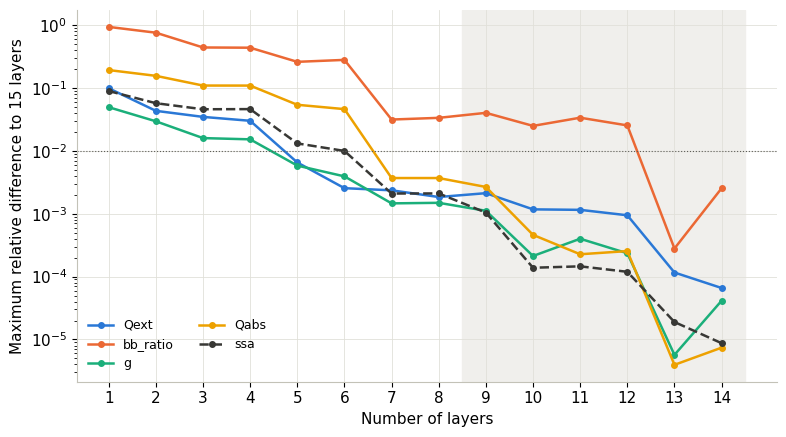

In [9]:
conv = {}
for v, a in [('Qext', 'none'), ('bb_ratio', 'none'), ('g', 'none'), ('Qabs', 'pigment'), ('ssa', 'pigment')]:
    d = ds[v].sel(absorption=a)
    conv[v] = np.abs(d / d.sel(n_layers=15) - 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
for (v, e), c, ls in zip(conv.items(), CAT + ['#383835'], ['-', '-', '-', '-', '--']):
    ax.semilogy(n_layers[:-1], e.max(('wall', 'wl', 'psd')).values[:-1], 'o', ls=ls, ms=4, color=c, label=v)
ax.axhline(0.01, color='#5f5e5a', lw=0.8, ls=':')
ax.axvspan(8.5, 14.5, color='#f0efec', zorder=-2)
ax.set_xticks(n_layers[:-1])
ax.set_xlabel('Number of layers')
ax.set_ylabel('Maximum relative difference to 15 layers')
ax.legend(frameon=False, ncol=2)
plt.tight_layout()

table = pd.DataFrame({v: e.max(('wl', 'psd')).to_pandas().T.stack() for v, e in conv.items()})
table.index.names = ['number of layers', 'wall']
(100 * table).round(1).unstack('wall').loc[[1, 2, 3, 4, 5, 7, 8, 9, 12, 14]]

### Backscattering spectra

$Q_{bb}$ of pigmented cells for the three walls and models of 1, 2, 4, 8 and 15 layers.

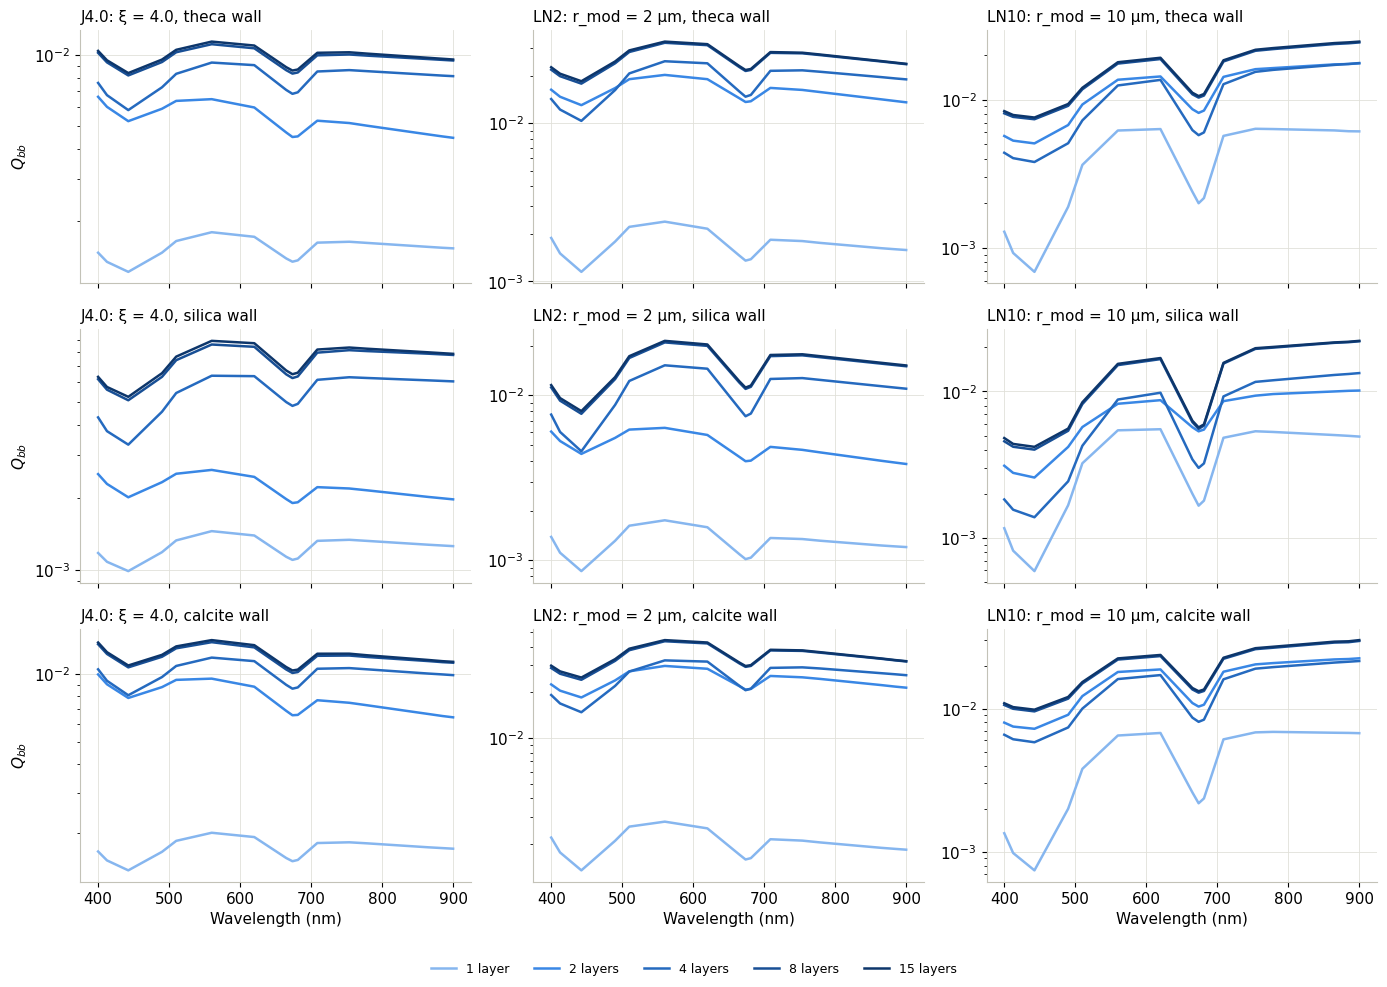

In [10]:
sel_n = [1, 2, 4, 8, 15]
psds = ['J4.0', 'LN2', 'LN10']
fig, axs = plt.subplots(len(walls), len(psds), figsize=(14, 3.3 * len(walls)), sharex=True)
for i, wall in enumerate(walls):
    for j, p in enumerate(psds):
        ax = axs[i, j]
        for n, c in zip(sel_n, N_COLORS):
            ax.plot(wl, ds.Qbb.sel(absorption='pigment', wall=wall, psd=p, n_layers=n), color=c,
                    label=f'{n} layer' + ('s' if n > 1 else ''))
        ax.set_yscale('log')
        ax.set_title(f'{p}: {psd_def[p][1]}, {wall} wall', loc='left')
    axs[i, 0].set_ylabel('$Q_{bb}$')
for ax in axs[-1]:
    ax.set_xlabel('Wavelength (nm)')
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='lower center', ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))

### Scattering matrix

Non-absorbing cells with a theca at 560 nm, for models of 1, 2, 4, 8 and 15 layers.

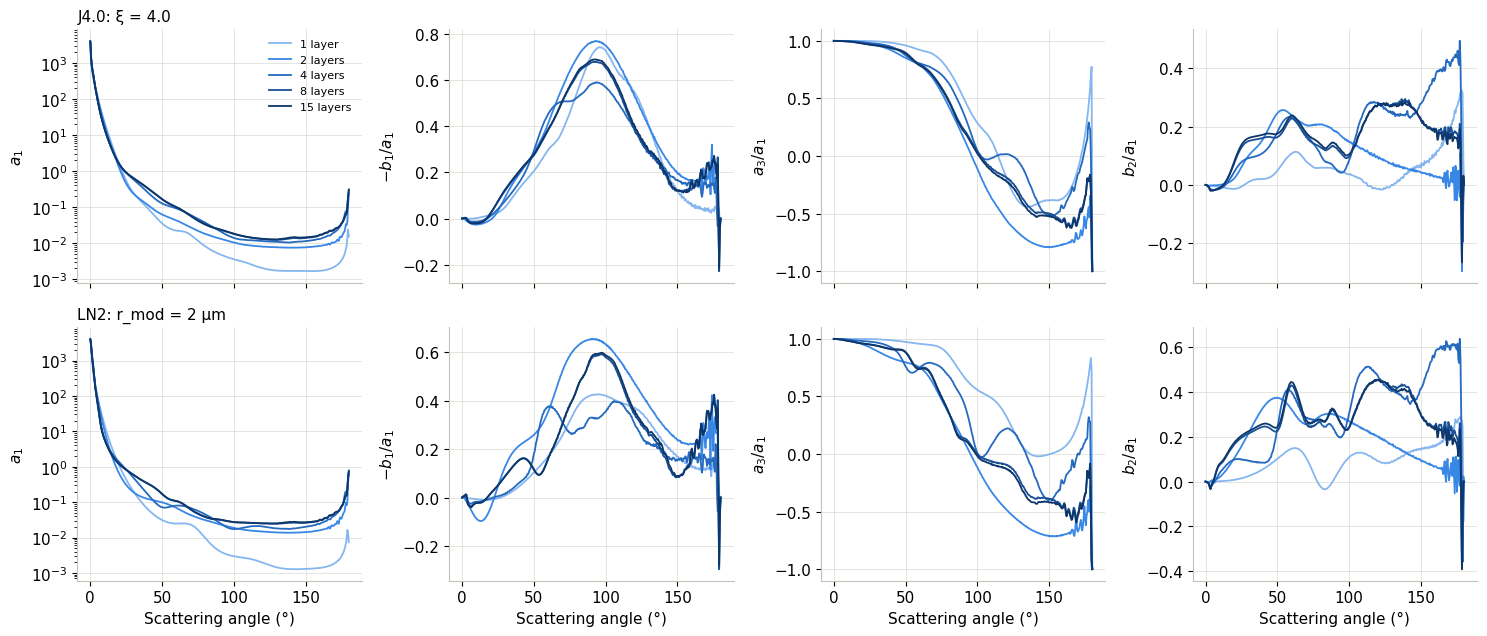

In [11]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds.sel(absorption='none', wl=560, psd=p, wall='theca')
    for n, c in zip(sel_n, N_COLORS):
        d = s.sel(n_layers=n)
        a1 = d.F.sel(element='a1')
        for j, (v, label) in enumerate(panels):
            y = a1 if v == 'a1' else d.dolp if v == 'dolp' else d.F.sel(element=v) / a1
            axs[i, j].plot(d.theta, y, color=c, lw=1.3, label=f'{n} layer' + ('s' if n > 1 else ''))
            axs[i, j].set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### Effect of the membranes

Ratio of the 15-layer cell (membranes resolved) to the 8-layer cell (membranes merged into the neighboring
compartments, same volume-averaged index), non-absorbing, 560 nm.

In [12]:
sub = ds.sel(absorption='none', wl=560)
rows = {}
for v in ['Qext', 'Qbb', 'bb_ratio', 'g']:
    for wall in walls:
        rows[(v, wall)] = (sub[v].sel(wall=wall, n_layers=15) / sub[v].sel(wall=wall, n_layers=8)).to_pandas()
pd.DataFrame(rows).T.round(3)

psd                J3.5   J4.0    LN1    LN2    LN5   LN10
Qext     theca    0.999  0.999  0.999  0.999  1.000  1.000
         silica   0.999  0.999  0.999  0.999  1.000  1.000
         calcite  0.999  0.999  0.999  0.999  1.000  1.000
Qbb      theca    1.018  1.024  1.007  1.016  1.016  1.019
         silica   1.024  1.034  1.017  1.022  1.015  1.020
         calcite  1.018  1.021  1.006  1.017  1.023  1.021
bb_ratio theca    1.019  1.025  1.009  1.017  1.016  1.019
         silica   1.025  1.035  1.018  1.023  1.015  1.020
         calcite  1.018  1.022  1.008  1.018  1.022  1.020
g        theca    1.000  1.000  1.000  0.999  0.999  0.999
         silica   1.000  1.000  1.000  1.000  0.999  0.999
         calcite  0.999  1.000  1.000  0.999  0.999  0.999

## Main results

All the models have the same volume-averaged refractive index and pigment content; they differ only by how much
of the internal structure of the 15-layer cell they resolve.

* **The homogeneous cell (1 layer) misses most of the backscattering.** The 15-layer cell has a backscattering
  ratio 2.8 to 16 times higher (×6–8 for the Junge distributions, up to ×16 for LN2), while $Q_{ext}$ changes by
  less than 11 %, $g$ by 2–5 % and $Q_{abs}$ by −16 to +10 %.
* **The large high-index structures near the surface carry the signal.** The steps that change $\tilde{b}_b$ are:
  * the **wall** (2 layers): ×2.1–8.3 for the theca, ×1.2–3.4 for the silica frustule and ×2.7–11 for the
    calcite coccoliths, compared with the homogeneous cell,
  * the **chloroplast region** (3 layers, up to ×3.0) and the **chloroplast and thylakoid boundaries** (5 to 7
    layers, ×0.9–1.5 at each step).

  The **nucleus** (4 layers, ×0.99–1.05) and the **nucleolus** (8 layers, < 1 %) hardly matter, being deep inside the
  cell and of low contrast with the cytoplasm.
* **Seven layers are enough** (wall, peripheral region, chloroplast stroma–thylakoids–stroma, cytoplasm, nucleus):
  the 7-layer model reproduces the 15-layer cell within 3.4 % for $\tilde{b}_b$ and $Q_{bb}$ and within 0.4 % for
  $Q_{ext}$, $g$, $Q_{abs}$ and the single scattering albedo, for all walls, size distributions and bands.
  Below 5 layers, the errors on $\tilde{b}_b$ exceed 25 %.
* **The lipid bilayer membranes** (8 nm, $m$ = 1.09) increase $\tilde{b}_b$ and $Q_{bb}$ by 0–3.5 % (15 vs 8 layers,
  the membranes being merged into the neighboring compartments in the 8-layer model) and leave $Q_{ext}$ and $g$
  unchanged (< 0.1 %). Their effect is small but not negligible for backscattering, and it requires resolving
  all the membranes: the error stays at 1.6–4 % until 12 layers.
* **The wall type remains a first-order factor for the 15-layer cell**: $\tilde{b}_b$ is 1.2–2.2 times higher with
  calcite than with silica, and up to 1.6 times higher with the cellulose theca.
* **The polarized elements** of the scattering matrix ($-b_1/a_1$, $a_3/a_1$, $b_2/a_1$) also converge by about
  8 layers, while the homogeneous and 2-layer models give clearly different angular shapes.

These results are for concentric spherical layers with fixed indices and volume fractions. The convergence order
depends on the assumed cell anatomy (here a peripheral chloroplast); real cells, with discrete plastids and
off-centered nuclei, will smooth the angular features.

## 5. Saving the results

In [13]:
ofile = odir / 'sensitivity_number_of_layers.nc'
ds.drop_vars('theta_rad').assign_attrs(
    refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
    radius_range_um=f'{r_min}-{r_max}', method='multilayer Mie theory (scattnlay)',
    layers='; '.join(f'{name.strip()}: m={m}, {kind}={size}' for name, m, kind, size in LAYERS),
    splits=str(SPLITS)).to_netcdf(ofile, encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_number_of_layers.nc 68.9 MB
